# Linear elasticity

A clamped beam deforming under its own weight, following the linear elasticity
chapter of the [FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/) and the
elasticity demo among the [DOLFINx demos](https://docs.fenicsproject.org/dolfinx/main/python/demos.html).
The displacement $u$ solves

$$ -\nabla\cdot\sigma(u) = f \ \text{ in } \Omega, \qquad u = 0 \ \text{ on } \Gamma_D, \qquad \sigma(u)\,n = 0 \ \text{ on } \partial\Omega\setminus\Gamma_D, $$

with the strain $\varepsilon(u) = \tfrac12(\nabla u + \nabla u^T)$ and the stress
$\sigma(u) = \lambda\,\mathrm{tr}(\varepsilon)\,I + 2\mu\,\varepsilon$.
The beam occupies $(0,L)\times(0,W)\times(0,W)$, is clamped at $x=0$ and loaded by gravity
$f = (0, 0, -\rho g)$.  The weak form is: find $u \in V_0$ with

$$ \int_\Omega \sigma(u) : \varepsilon(v) \, dx = \int_\Omega f \cdot v \, dx \qquad \forall v \in V_0 . $$

## Mesh, space and material

`BoxMesh` creates a tetrahedral mesh.  As in Firedrake its faces are numbered 1 ($x=0$),
2 ($x=L$), 3 ($y=0$), 4 ($y=W$), 5 ($z=0$) and 6 ($z=W$).  The front end follows the
Firedrake API, so apart from the clearly marked extras the code reads as Firedrake code.

In [1]:
from ngsufl import *

L, W = 1.0, 0.2
mesh = BoxMesh(10, 3, 3, L, W, W)
V = VectorFunctionSpace(mesh, "CG", 2)
print(V.dim(), "dofs")

delta = W / L
gamma = 0.4 * delta**2
rho, g = 1.0, gamma
mu, lmbda = 1.0, 1.25

3087 dofs


## Variational problem

The stress is a symmetric $3\times3$ matrix expression, written in the same way as on paper.

In [2]:
def epsilon(u):
    return sym(grad(u))


def sigma(u):
    return lmbda * tr(epsilon(u)) * Identity(len(u)) + 2 * mu * epsilon(u)


u, v = TrialFunction(V), TestFunction(V)
f = Constant((0.0, 0.0, -rho * g))

a = inner(sigma(u), epsilon(v)) * dx
L_form = dot(f, v) * dx

## Clamping and solution

The Dirichlet condition is imposed on boundary 1 ($x=0$).  Direct solvers are the
default; for large 3D problems one would select `cg` with a preconditioner through
`solver_parameters`.

In [3]:
bc = DirichletBC(V, Constant((0.0, 0.0, 0.0)), 1)
uh = Function(V, name="u")
solve(a == L_form, uh, bcs=bc)

tip = uh.at(L, W / 2, W / 2)
print("tip displacement:", tip)

tip displacement: (-8.12696949898696e-06, 8.99969989966386e-05, -0.23893635678533146)


## Deformed shape

`plot` is an ngsufl convenience (Firedrake would write a VTK file).  For a 3D mesh it draws
the boundary surface coloured by the given function.  With
`deformation=` the surface is moved by a vector field, here the
displacement itself (`deformation=10 * uh` would exaggerate it).

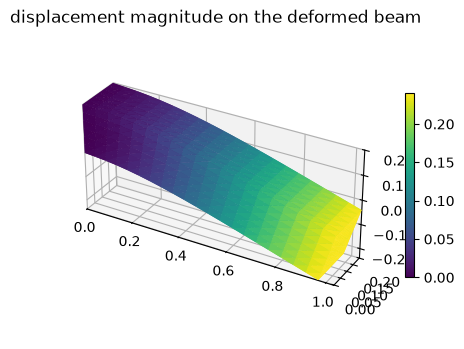

In [4]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(9, 4))
ax = fig.add_subplot(projection="3d")
plot(sqrt(dot(uh, uh)), ax=ax, deformation=uh, subdivision=2)
ax.set_aspect("equal")
ax.set_title("displacement magnitude on the deformed beam");

## Von Mises stress

The von Mises stress $\sigma_M = \sqrt{\tfrac32\, s:s}$ with the deviator
$s = \sigma - \tfrac13\mathrm{tr}(\sigma) I$ is a derived quantity.  We project it onto a
discontinuous space and plot it.

In [5]:
s = sigma(uh) - tr(sigma(uh)) / 3 * Identity(3)
von_Mises = sqrt(1.5 * inner(s, s))

Q = FunctionSpace(mesh, "DG", 1)
stress = project(von_Mises, Q)
stress.name = "von Mises"
print("max von Mises stress:", stress.dat.data.max())

max von Mises stress: 0.17714560082663064


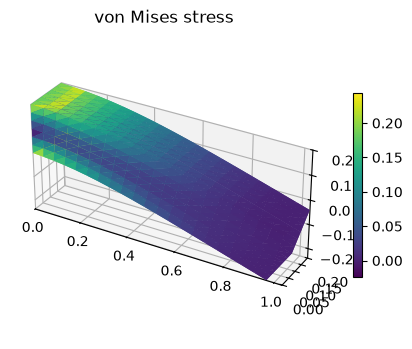

In [6]:
fig = plt.figure(figsize=(9, 4))
ax = fig.add_subplot(projection="3d")
plot(stress, ax=ax, deformation=uh, subdivision=2)
ax.set_aspect("equal")
ax.set_title("von Mises stress");

## Comparison with plain NGSolve (ngsufl extra)

The same problem written directly with NGSolve objects should give the same
discrete solution up to round-off, since both use the same space and the same
exact quadrature.  UFL is only a different front door to the NGSolve integrators.

In [7]:
import ngsolve as ngs

m = mesh.ngs
fes = ngs.VectorH1(m, order=2, dirichlet="back")
U, Wt = fes.TnT()
E = lambda w: ngs.Sym(ngs.Grad(w))
S = lambda w: lmbda * ngs.Trace(E(w)) * ngs.Id(3) + 2 * mu * E(w)

A = ngs.BilinearForm(ngs.InnerProduct(S(U), E(Wt)) * ngs.dx).Assemble()
F = ngs.LinearForm(ngs.CF((0, 0, -rho * g)) * Wt * ngs.dx).Assemble()
gf = ngs.GridFunction(fes)
gf.vec.data = A.mat.Inverse(fes.FreeDofs()) * F.vec

tip_ngs = gf(m(L, W / 2, W / 2))
print("native NGSolve tip:", tip_ngs)
print("difference of tip values:", max(abs(a_ - b_) for a_, b_ in zip(tip, tip_ngs)))
print("L2 difference of fields:", ngs.sqrt(ngs.Integrate((uh.gf - gf)**2, m)))

native NGSolve tip: (-8.12696949897048e-06, 8.999699898307517e-05, -0.23893635678536465)
difference of tip values: 3.319566843629218e-14
L2 difference of fields: 3.569082370495958e-15
